In [14]:
#loading necessary libraries
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
#Loading the training dataset 
train_df = pd.read_csv(r"C:\Users\sanke\Desktop\SwahiliTranslate AI\data\raw\train.tsv", sep="\t")
train_df.head()

,en,swa
0,Polychromed woodcarving of an Orixá by Luiz Pa...,Kinyago cha mtumwa mweusi kilichochongwa na Lu...
1,Photo by Children At Risk Foundation,Picha kwa hisani ya Asasi ya Watoto Walio Hata...
2,Angola and Brazil have a special relationship ...,Angola na Brazil zina uhusiano maalum baina ya...
3,"Since 2000, commerce between the two countries...","Tangu mwaka 2000, biashara kati ya mataifa hay..."
4,According to the Association of Brazilian Comp...,Kwa mujibu wa Chama cha Makampuni ya KiBrazili...


In [6]:
#dataset size 
train_df.shape

(30782, 2)

In [7]:
#checking column names 
train_df.columns

Index(['en', 'swa'], dtype='object')

In [8]:
#checking for missing values 
train_df.isnull().sum()

en     0
swa    0
dtype: int64

In [11]:
#cheking for duplicates
print(train_df.duplicated().sum())

445


In [10]:
train_df.sample(5)

,en,swa
21172,"Nine bloggers and journalists, four of them Gl...","Wanablogu na waandishi tisa, wanne wakiwa wana..."
28390,"The next day following the meeting, however, s...","Siku ya pili baada ya mkutano huo, hata hivyo,..."
24219,Schools reopen this week in ‪#‎Nepal‬ after th...,Sule zimefunguliwa wiki hii nchini ‪#‎Nepal‬i ...
13828,Blood donation drive in Shahbag Square for the...,uchangiaji wa damu unaendelea katika eneo la w...
29361,The news has raised concerns about censorship ...,Habari hiyo imeamsha hisia kuhusu udhibiti huo...


In [12]:
# Calculate the number of words in each English sentence
train_df["en_length"] = train_df["en"].apply(lambda x: len(x.split()))

# Calculate the number of words in each Kiswahili sentence
train_df["swa_length"] = train_df["swa"].apply(lambda x: len(x.split()))

# Display the first five results
train_df[["en_length", "swa_length"]].head()

,en_length,swa_length
0,10,10
1,6,9
2,41,44
3,16,14
4,20,25


In [13]:
# Descriptive statistics for sentence lengths
train_df[["en_length", "swa_length"]].describe()

,en_length,swa_length
count,30782.000000,30782.000000
mean,18.293288,18.719446
std,11.997861,12.685085
min,1.000000,1.000000
25%,9.000000,9.000000
50%,16.000000,16.000000
75%,25.000000,25.000000
max,155.000000,161.000000


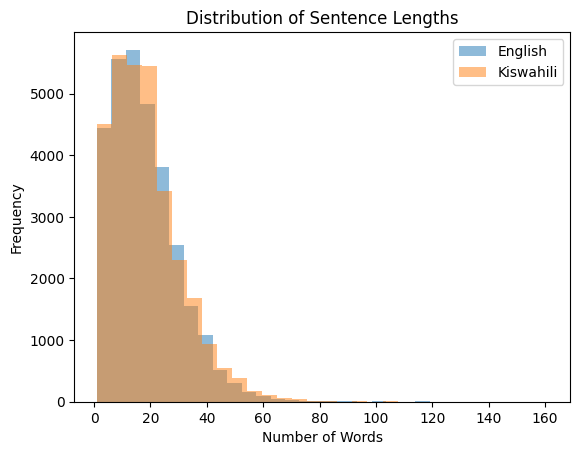

In [15]:
#visualizing the distribution of sentence lengths
plt.hist(train_df["en_length"], bins=30, alpha=0.5, label="English")
plt.hist(train_df["swa_length"], bins=30, alpha=0.5, label="Kiswahili")

plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.title("Distribution of Sentence Lengths")
plt.legend()
plt.show()

# Interpreting the Histogram 
- Most English and Kiswahili sentences contain approximately 5 to 30 words
- Both languages have a similar distribution of sentence lengths 

In [17]:
# Calculate correlation between English and Kiswahili sentence lengths
print(train_df["en_length"].corr(train_df["swa_length"]))

0.9222644335259629


- English sentences with more words tend to have Kiswahili translations with more words.